<div style="text-align:center;">

# 📊 Customer Data Analysis for Business Insights

</div>

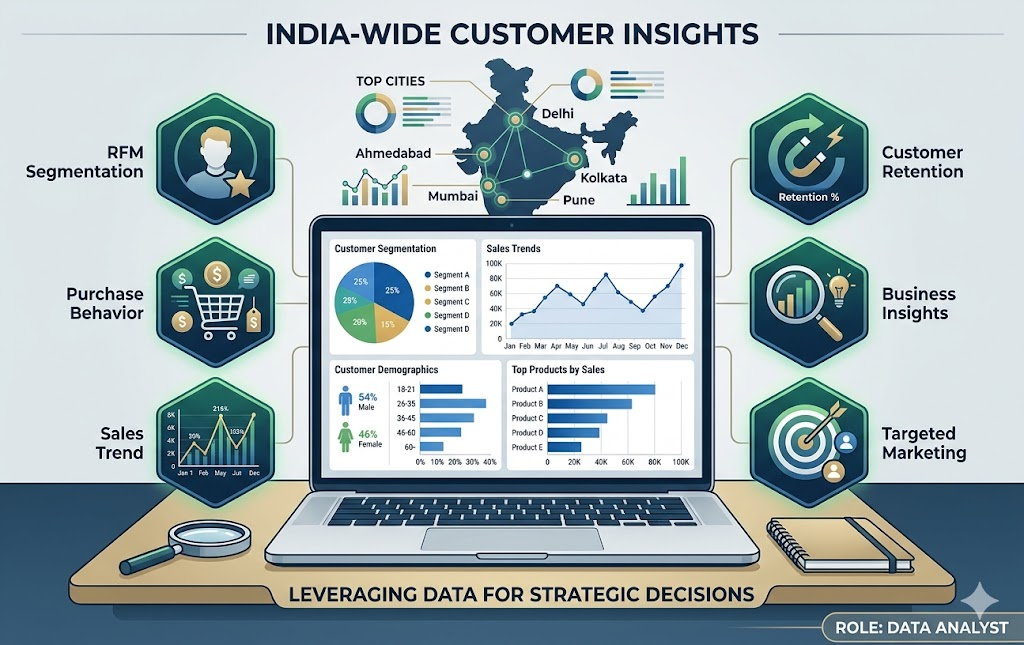!

## 🚀Project Overview

This project is based on customer retail data from a mid-sized Indian company. Although the company had customer and transaction data, they were not able to properly understand their customers. This led to generic marketing strategies, high customer attrition, and low retention.

In this project, I used Python 🐍 to clean and process the data, analyze customer behavior, and perform RFM analysis to identify high-value customers. I also created visualizations to highlight key patterns and provided actionable insights to help improve targeted marketing and customer retention.

## Analytical Workflow
0. Import the Liabilities
1. Loading the Data
2. Data Cleaning
3. Merge Customer Data and Transactions Data
4. RFM Analysis
5. Customer Segmentation
6. Visualization & Business Insights

## Step 0 : Import Liabrary

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 📥 Step 1: Data Loading & Understanding

In [6]:
df_cust = pd.read_csv("Customer_Master_Data.csv",encoding = "latin1")
df_trans = pd.read_csv("Customer_Transactions.csv",encoding = "latin1")

### Since we have two datasets, one for Customer one for Transactions, we are going to focus on one Customer and then Transactuions.

### 👁 Preview the Data
Customer Dataset

In [7]:
df_cust.head()

,CustomerID,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10000,Onkar Bhargava,pkeer@yahoo.com,Male,54,Delhi,Divorced,0,2021-02-22
1,CUST10001,Divit Kohli,mkalita@sarin.com,Female,48,Kolkata,Married,0,2023-12-06
2,CUST10002,Kiara Behl,apteanay@hotmail.com,Male,75,Kolkata,Widowed,2,2023-08-23
3,CUST10003,Vaibhav Sankar,bseshadri@choudhry.info,Male,62,Pune,Divorced,2,2022-11-17
4,CUST10004,Shray DâAlia,bdhillon@toor-mall.com,Male,55,Delhi,Divorced,0,2022-12-04


In [8]:
df_trans.head()

,CustomerID,TransactionDate,TransactionAmount
0,CUST10771,7/31/23,2383.07
1,CUST10100,3/10/24,497.54
2,CUST10031,2/17/25,536.78
3,CUST10987,7/17/23,314.89
4,CUST10831,12/15/24,2543.19


### 💾 Review Dataset Structure

### 👩‍👩‍👧‍👧 Customer Data :

In [9]:
print(df_cust.shape)
print('------------------')
print(df_cust.columns)
print('------------------')
df_cust.info()

(1000, 9)
------------------
Index(['CustomerID', 'Name', 'Email', 'Gender', 'Age', 'City', 'MaritalStatus',
       'NumChildren', 'JoinDate'],
      dtype='object')
------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     1000 non-null   object
 1   Name           1000 non-null   object
 2   Email          1000 non-null   object
 3   Gender         1000 non-null   object
 4   Age            1000 non-null   int64 
 5   City           1000 non-null   object
 6   MaritalStatus  1000 non-null   object
 7   NumChildren    1000 non-null   int64 
 8   JoinDate       1000 non-null   object
dtypes: int64(2), object(7)
memory usage: 70.4+ KB


### 🧾 Transaction Data :

In [10]:
print(df_trans.shape)
print('------------------')
print(df_trans.columns)
print('------------------')
df_trans.info()

(23050, 3)
------------------
Index(['CustomerID', 'TransactionDate', 'TransactionAmount'], dtype='object')
------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         23050 non-null  object 
 1   TransactionDate    23050 non-null  object 
 2   TransactionAmount  23050 non-null  float64
dtypes: float64(1), object(2)
memory usage: 540.4+ KB


### 📌Since join date of customer should be Datetime, hence we have to convert it

In [11]:
df_cust['JoinDate'] = pd.to_datetime(df_cust['JoinDate'])
df_trans['TransactionDate'] = pd.to_datetime(df_trans['TransactionDate'])

C:\Users\Megha Solanki\AppData\Local\Temp\ipykernel_7664\2362240279.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_trans['TransactionDate'] = pd.to_datetime(df_trans['TransactionDate'])


In [12]:
df_cust.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   CustomerID     1000 non-null   object        
 1   Name           1000 non-null   object        
 2   Email          1000 non-null   object        
 3   Gender         1000 non-null   object        
 4   Age            1000 non-null   int64         
 5   City           1000 non-null   object        
 6   MaritalStatus  1000 non-null   object        
 7   NumChildren    1000 non-null   int64         
 8   JoinDate       1000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(6)
memory usage: 70.4+ KB


In [13]:
df_trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         23050 non-null  object        
 1   TransactionDate    23050 non-null  datetime64[ns]
 2   TransactionAmount  23050 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 540.4+ KB


# Step 2 :🧹 Data Cleaning

#### 🗑 Remove duplicates

In [14]:
df_cust.duplicated().sum()

np.int64(0)

In [15]:
df_trans.duplicated().sum()

np.int64(0)

#### 🔎 Check missing values

In [16]:
print(df_cust.isnull().sum())
print(df_trans.isnull().sum())

CustomerID       0
Name             0
Email            0
Gender           0
Age              0
City             0
MaritalStatus    0
NumChildren      0
JoinDate         0
dtype: int64
CustomerID           0
TransactionDate      0
TransactionAmount    0
dtype: int64


In [17]:
df_cust.describe()

,Age,NumChildren,JoinDate
count,1000.000000,1000.000000,1000
mean,46.471000,1.311000,2022-07-24 01:36:28.800000256
min,18.000000,0.000000,2020-07-29 00:00:00
25%,32.000000,0.000000,2021-07-12 12:00:00
50%,46.000000,1.000000,2022-07-10 12:00:00
75%,60.000000,2.000000,2023-08-05 12:00:00
max,75.000000,4.000000,2024-07-28 00:00:00
std,16.582525,1.190671,NaN


In [18]:
df_cust.describe(include = 'object')

,CustomerID,Name,Email,Gender,City,MaritalStatus
count,1000,1000,1000,1000,1000,1000
unique,1000,993,1000,3,10,4
top,CUST10000,Anahita Buch,pkeer@yahoo.com,Female,Lucknow,Widowed
freq,1,2,1,340,110,280


In [19]:
df_trans.describe()

,TransactionDate,TransactionAmount
count,23050,23050.000000
mean,2024-01-22 02:29:03.618221312,1000.138814
min,2020-08-22 00:00:00,3.870000
25%,2023-05-07 00:00:00,482.107500
50%,2024-04-21 00:00:00,844.755000
75%,2024-12-12 00:00:00,1346.795000
max,2025-07-29 00:00:00,6890.190000
std,NaN,703.358978


In [20]:
df_trans.describe(include = 'object')

,CustomerID
count,23050
unique,1000
top,CUST10851
freq,38


### 💡 Summary : Data is free of any null or duplicated data. The types of Data are also in order, therefore we can procide ahead with Transfermation as rquired.

# Step 3 : 🔀 Merge Customer Data and Transactions Data

### 🔑 Identify Common Key

The datasets are connected through the common identifier CustomerID, which enables integration of customer demographics (customer) with their transaction history (transaction) for analysis.

- customer → Customer details
- transactions → Transaction records"

In [21]:
df_final = pd.merge(df_trans, df_cust, on ='CustomerID', how ='left')

In [22]:
df_final.head()

,CustomerID,TransactionDate,TransactionAmount,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10771,2023-07-31,2383.07,Lakshay Dhillon,dharmajantara@gmail.com,Female,27,Ahmedabad,Widowed,3,2023-05-31
1,CUST10100,2024-03-10,497.54,Aniruddh Borah,jivikabhavsar@gmail.com,Female,53,Lucknow,Divorced,4,2022-01-08
2,CUST10031,2025-02-17,536.78,Ritvik Ahuja,jhaverifarhan@chandra.org,Male,40,Ahmedabad,Single,0,2023-12-03
3,CUST10987,2023-07-17,314.89,Jayan Wagle,ojas82@gmail.com,Not Disclosed,75,Bangalore,Widowed,4,2022-03-18
4,CUST10831,2024-12-15,2543.19,Ishita Agarwal,vbalay@yahoo.com,Not Disclosed,27,Jaipur,Divorced,4,2021-06-30


### ✅ Check Final Dataset Structure

In [23]:
df_final.shape

(23050, 11)

In [24]:
df_final.columns

Index(['CustomerID', 'TransactionDate', 'TransactionAmount', 'Name', 'Email',
       'Gender', 'Age', 'City', 'MaritalStatus', 'NumChildren', 'JoinDate'],
      dtype='object')

In [25]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         23050 non-null  object        
 1   TransactionDate    23050 non-null  datetime64[ns]
 2   TransactionAmount  23050 non-null  float64       
 3   Name               23050 non-null  object        
 4   Email              23050 non-null  object        
 5   Gender             23050 non-null  object        
 6   Age                23050 non-null  int64         
 7   City               23050 non-null  object        
 8   MaritalStatus      23050 non-null  object        
 9   NumChildren        23050 non-null  int64         
 10  JoinDate           23050 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(1), int64(2), object(6)
memory usage: 1.9+ MB


In [26]:
df_final.isnull().sum()

CustomerID           0
TransactionDate      0
TransactionAmount    0
Name                 0
Email                0
Gender               0
Age                  0
City                 0
MaritalStatus        0
NumChildren          0
JoinDate             0
dtype: int64

### 🔍 Observations
- Successfully merged both datasets using CustomerID
- Each transaction is now linked with customer details (age, city, etc.)
- Enables segmentation based on demographics

### 💰 Total Revenue

In [27]:
total_revenue = df_final['TransactionAmount'].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 23053199.66


### 📈 Revenue Over Time

<Axes: title={'center': 'Monthly Revenue Trend'}, xlabel='TransactionDate'>

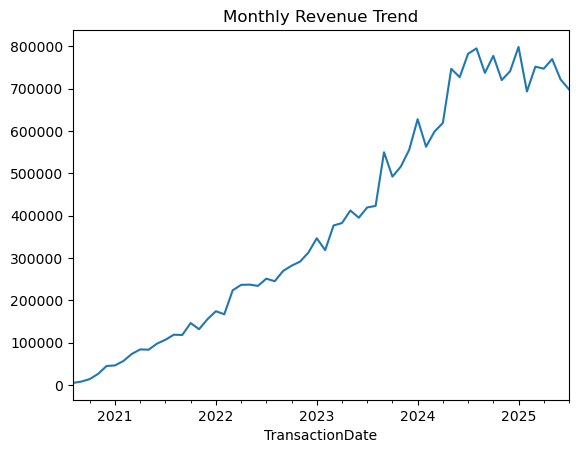

In [28]:
monthly_sales = df_final.groupby(df_final['TransactionDate'].dt.to_period('M'))['TransactionAmount'].sum()

monthly_sales.plot(kind='line', title='Monthly Revenue Trend')

###  ♀️♂️ Customer Distribution by Gender

<Axes: title={'center': 'Gender Distribution'}, xlabel='Gender'>

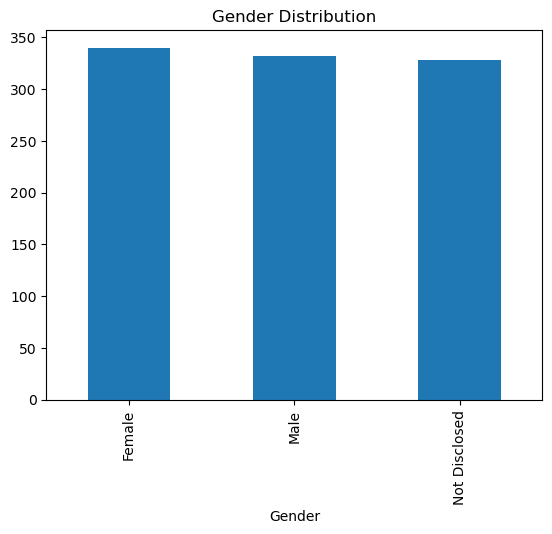

In [29]:
df_cust['Gender'].value_counts().plot(kind='bar', title='Gender Distribution')

### 🌍 Top Cities by Revenue

<Axes: title={'center': 'Top Cities by Revenue'}, xlabel='City'>

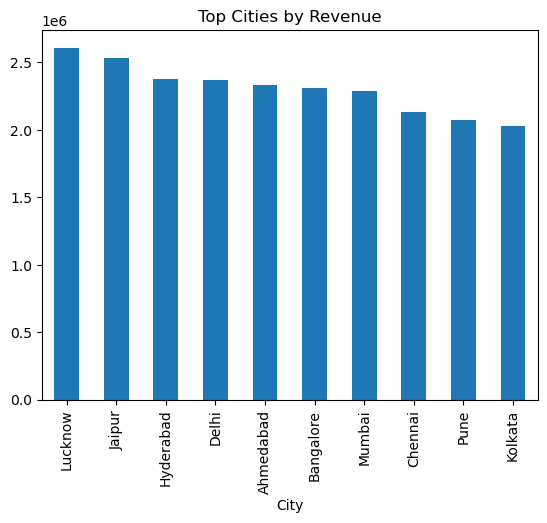

In [30]:
top_cities = df_final.groupby('City')['TransactionAmount'].sum().sort_values(ascending=False).head(10)

top_cities.plot(kind='bar', title='Top Cities by Revenue')

### 💰 Top 10 Customers

<Axes: title={'center': 'Top 10 Customers'}, xlabel='CustomerID'>

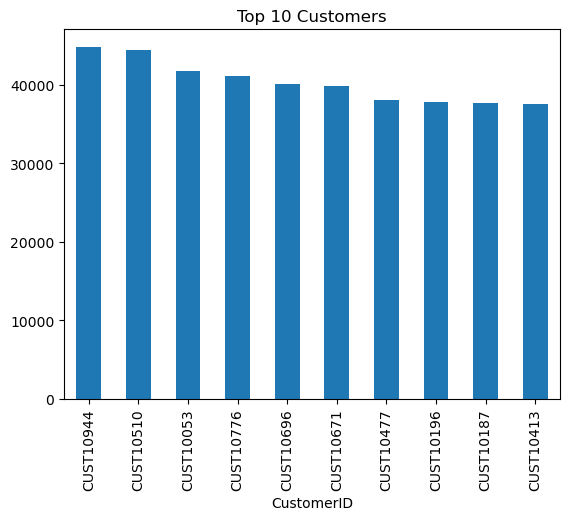

In [31]:
top_cust = df_final.groupby('CustomerID')['TransactionAmount'].sum().sort_values(ascending=False).head(10)

top_cust.plot(kind='bar', title='Top 10 Customers')

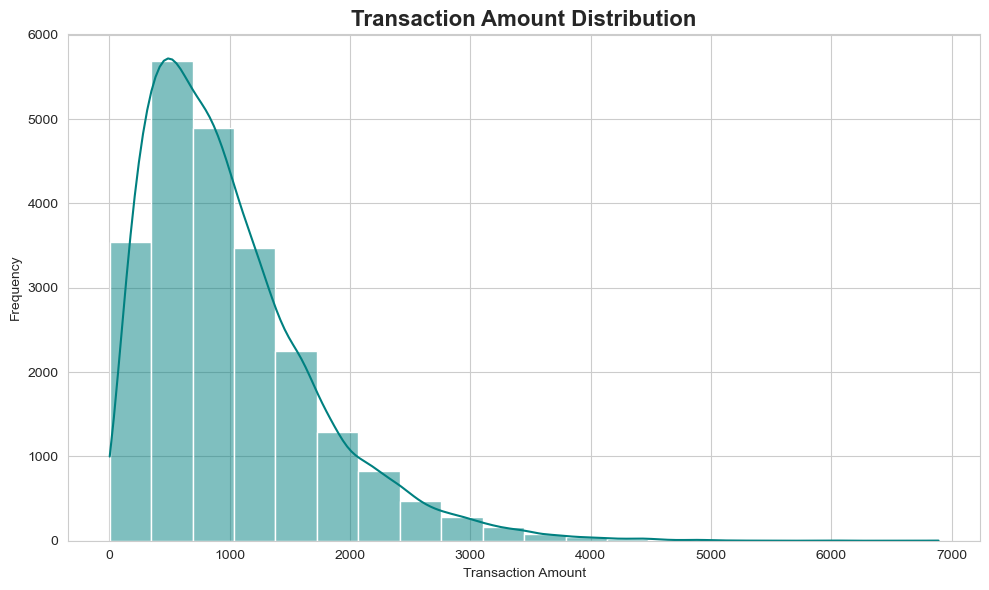

In [32]:
# Set style
sns.set_style("whitegrid")

# Create figure
plt.figure(figsize=(10,6))

# Histogram + KDE (density curve)
sns.histplot(
    df_final['TransactionAmount'],
    bins=20,
    kde=True,
    color='teal'
)

# Titles and labels
plt.title('Transaction Amount Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

# Layout
plt.tight_layout()

plt.show()

## 🎂 Customer Age Distribution

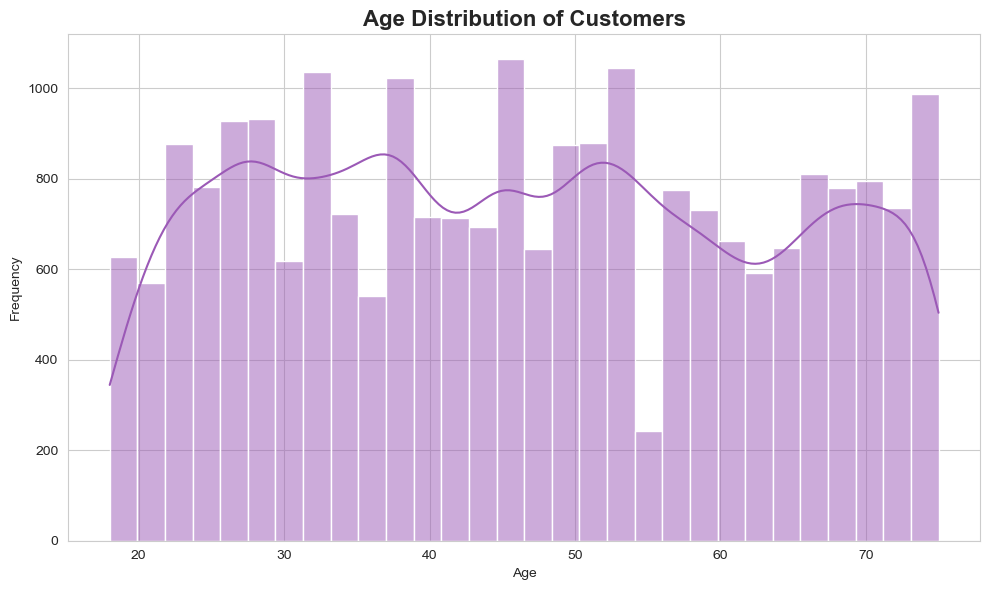

In [33]:
# Set style
sns.set_style("whitegrid")

# Create figure
plt.figure(figsize=(10,6))

# Histogram + KDE
sns.histplot(
    df_final['Age'],
    bins=30,
    kde=True,
    color= '#9b59b6'
)

# Titles and labels
plt.title('Age Distribution of Customers', fontsize=16, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### 🔍 Key Business Insights

- Identify high-value customers driving the majority of revenue
- Detect top-performing cities contributing to sales
- Analyze customer demographics (age, gender)
- Evaluate sales trends over time
- Understand spending patterns and distribution

### 📌 Conclusion of Step 3

Exploratory data analysis revealed key patterns in customer behavior, revenue trends, and demographics, enabling more targeted marketing strategies and improved business performance.

# 🧠 Step 4: RFM Analysis

## 📌 Objective

Segment customers based on purchasing behavior using:

- Recency
- Frequency
- Monetary

## 📖 Concept Explanation

#### RFM analysis evaluates customers based on:

- Recency (R): How recently a customer made a purchase
- Frequency (F): How often a customer makes purchases
- Monetary (M): How much money a customer spends

👉 This helps identify:

- High-value customers
- Loyal customers
- At-risk or inactive customers

### 🧮 Calculate RFM Metrics

In [34]:
reference_date = df_trans['TransactionDate'].max() + pd.Timedelta(days=1)

In [35]:
rfm = df_trans.groupby('CustomerID').agg({
    'TransactionDate': lambda x: (reference_date - x.max()).days,
    'CustomerID': 'count',
    'TransactionAmount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

In [36]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
CUST10000,13,23,21265.49
CUST10001,35,30,28654.31
CUST10002,18,24,23884.03
CUST10003,81,25,24206.03
CUST10004,8,19,25565.30


## 🔍 Observation:

- Recency → Days since last purchase
- Frequency → Number of transactions
- Monetary → Total amount spent

## RFM Scoring

In [37]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5,4,3,2,1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1,2,3,4,5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1,2,3,4,5])

### 🔍 Observations

- Recency is inversely scored (lower days = higher score)
- Frequency and Monetary are directly scored
- Customers are ranked into 5 levels (1–5)

In [38]:
rfm['RFM_Score'] = (rfm['R_Score'].astype(str) +rfm['F_Score'].astype(str) +rfm['M_Score'].astype(str))

In [39]:
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
CUST10000,13,23,21265.49,4,3,2,432
CUST10001,35,30,28654.31,3,5,5,355
CUST10002,18,24,23884.03,4,3,3,433
CUST10003,81,25,24206.03,1,4,3,143
CUST10004,8,19,25565.30,5,1,4,514


### 🔍 Observations

- Combined score helps identify customer value easily
- Example:
    - 555 → Best customers
    - 111 → Least valuable

# 🎯 Step 5: Customer Segmentation

## 📌 Objective

Classify customers into meaningful business segments

### 🧠 Segment Logic

In [58]:
def segment(row):
    R = int(row['R_Score'])
    F = int(row['F_Score'])
    M = int(row['M_Score'])

    if R >= 5 and F >= 5 and M >= 5:
        return 'Champions'
    elif R >= 4 and F >= 4:
        return 'Loyal Customers'
    elif R >= 4:
        return 'Potential Loyalists'
    elif R <= 2 and F >= 3:
        return 'At Risk'
    elif M == 5:
        return 'Highest Spent'
rfm['Segment'] = rfm.apply(segment, axis=1)

In [42]:
# Step 5: Improved RFM Customer Segmentation

def segment_customer(row):

    R = int(row['R_Score'])
    F = int(row['F_Score'])
    M = int(row['M_Score'])

    # 1. Champions: Recent, frequent, and high-spending customers
    if R >= 4 and F >= 4 and M >= 4:
        return 'Champions'

    # 2. Customers who were valuable but have become inactive
    elif R <= 2 and F >= 4 and M >= 4:
        return 'Cannot Lose Them'

    # 3. Customers with good purchasing frequency
    elif R >= 3 and F >= 4:
        return 'Loyal Customers'

    # 4. Recent customers with moderate purchasing frequency
    elif R >= 4 and F >= 2:
        return 'Potential Loyalists'

    # 5. Very recent customers with low purchasing frequency
    elif R >= 4 and F <= 2:
        return 'Recent Customers'

    # 6. Previously frequent customers who have become inactive
    elif R <= 2 and F >= 3:
        return 'At Risk'

    # 7. Customers who purchase infrequently and have not purchased recently
    elif R <= 2 and F <= 2:
        return 'Hibernating'

    # 8. Customers with moderate recency and frequency
    elif R == 3 and F == 3:
        return 'Need Attention'

    # 9. Default category for all remaining customers
    else:
        return 'Regular Customers'


# Apply segmentation to every customer
rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# Display the first five customers
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
CUST10000,13,23,21265.49,4,3,2,432,Potential Loyalists
CUST10001,35,30,28654.31,3,5,5,355,Loyal Customers
CUST10002,18,24,23884.03,4,3,3,433,Potential Loyalists
CUST10003,81,25,24206.03,1,4,3,143,At Risk
CUST10004,8,19,25565.30,5,1,4,514,Recent Customers


<Axes: title={'center': 'Customer Segments'}, xlabel='Segment'>

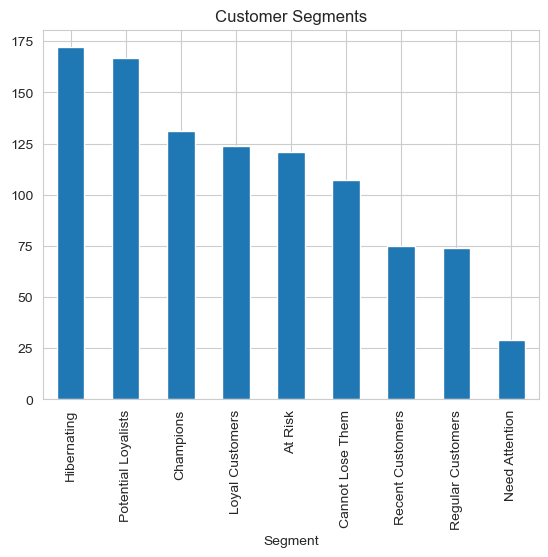

In [41]:
rfm['Segment'].value_counts().plot(kind='bar', title='Customer Segments')

#### 🎨 Customer Segments Chart (Seaborn)

In [43]:
segment_counts = rfm['Segment'].value_counts().reset_index()
segment_counts.columns = ['Segment', 'Count']

C:\Users\Megha Solanki\AppData\Local\Temp\ipykernel_7664\4175676694.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


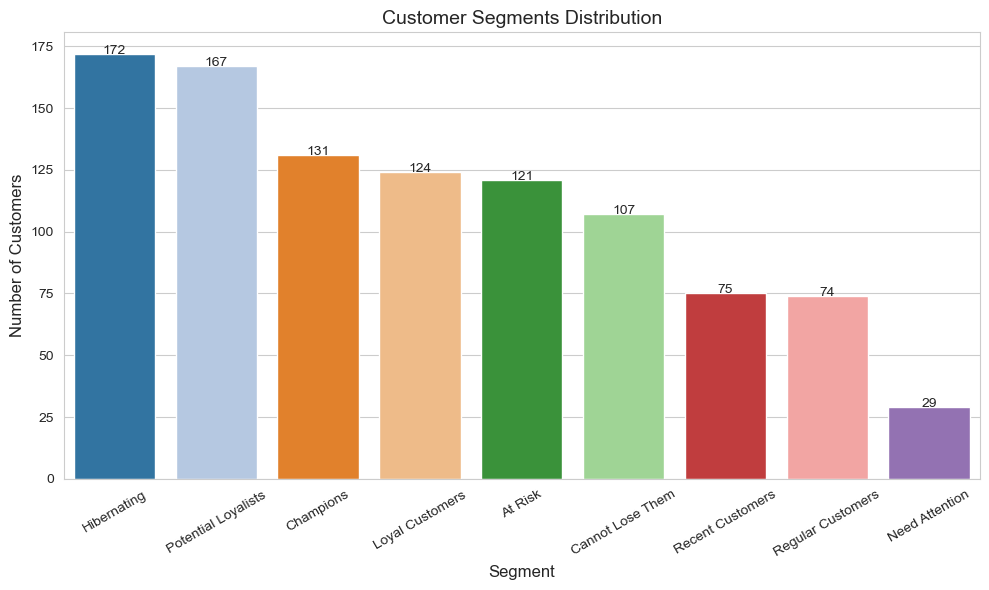

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.barplot(
    data=segment_counts,
    x='Segment',
    y='Count',
    palette='tab20'
)

plt.title("Customer Segments Distribution", fontsize=14)
plt.xlabel("Segment", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)
plt.xticks(rotation=30)

# Add labels on bars
for index, row in segment_counts.iterrows():
    plt.text(index, row['Count'], row['Count'], ha='center')

plt.tight_layout()
plt.show()

### 🔍 Observations

- **Champions:** High-value customers (recent, frequent, high spend)
- **Loyal Customers:** Frequent buyers with consistent engagement
- **Potential Loyalists:** Recent customers with growth potential
- **At Risk:** Previously active but now inactive
- **Hoghest Spent:** Highest amt Spent

# 📊 Step 6: Visualization & Business Insights

## 📌 Objective

- To visually analyze customer segments and extract actionable insights for marketing and retention strategies.

### 🔢 Customer Count by Segment

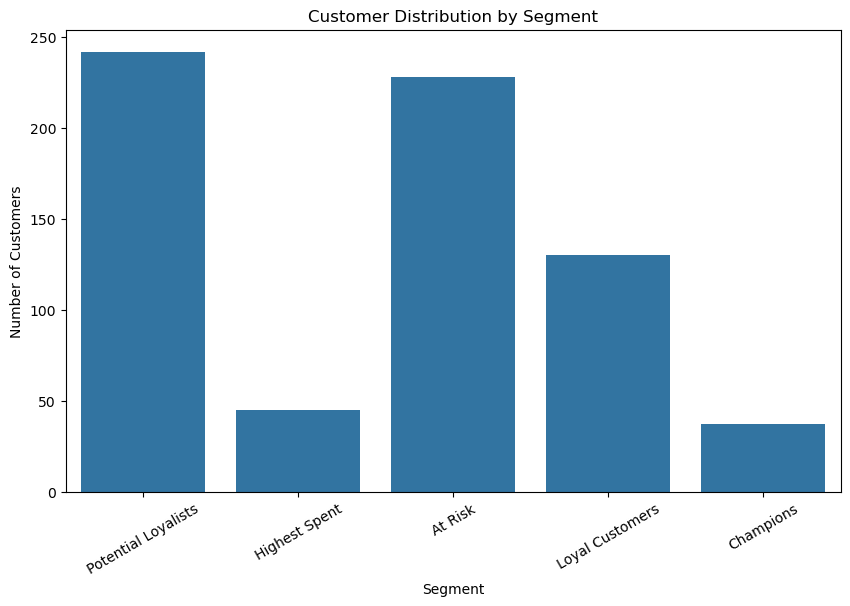

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.countplot(x='Segment', data=rfm)
plt.xticks(rotation=30)
plt.title("Customer Distribution by Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")

plt.show()

### 🔍 Observation:

- Shows how customers are distributed across segments
- Helps identify dominant customer groups

### 💰 Revenue Contribution by Segment

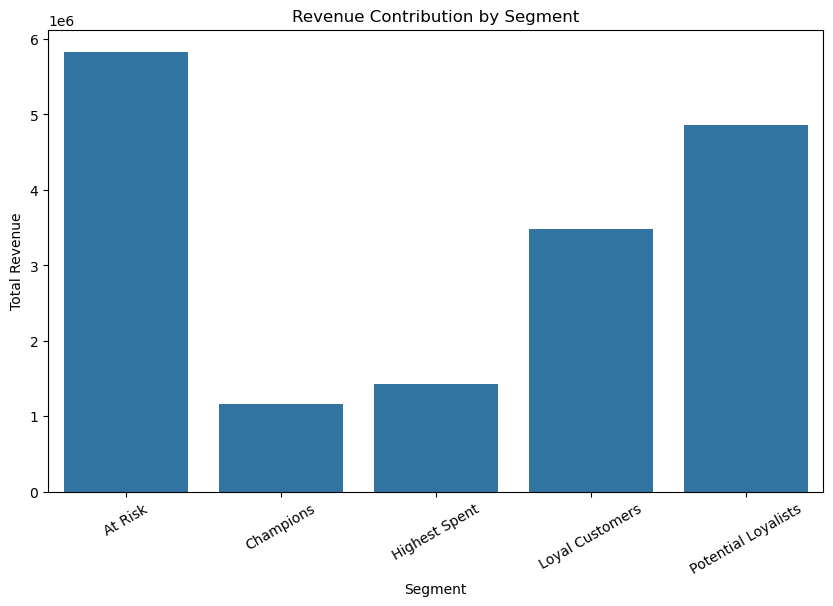

In [104]:
segment_revenue = rfm.groupby('Segment')['Monetary'].sum().reset_index()

plt.figure(figsize=(10,6))

sns.barplot(data=segment_revenue, x='Segment', y='Monetary')
plt.xticks(rotation=30)
plt.title("Revenue Contribution by Segment")
plt.xlabel("Segment")
plt.ylabel("Total Revenue")

plt.show()

### 🔍 Observation:

- Identifies which segments generate maximum revenue
- High-value segments (like Champions) contribute most

## 📉 Recency vs Monetary Scatter Plot

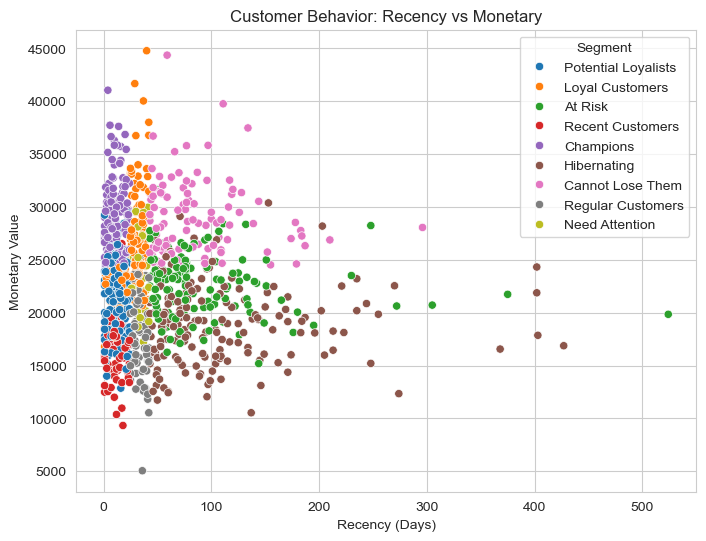

In [45]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Segment'
)

plt.title("Customer Behavior: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value")

plt.show()

### 🔍 Observation: 

- Customers with low recency (recent buyers) tend to spend more
- High recency customers may indicate churn risk

### 📈 Pareto Analysis (80/20 Rule)

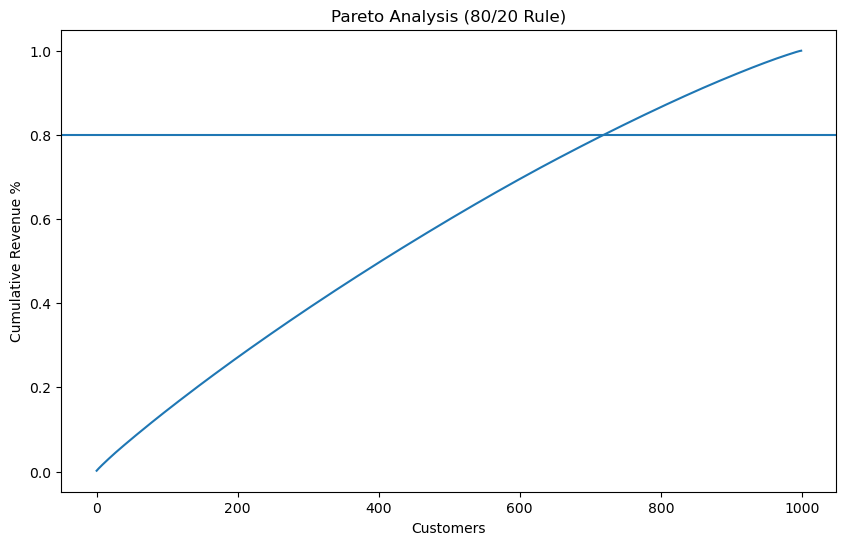

In [114]:
rfm_sorted = rfm.sort_values(by='Monetary', ascending=False)

rfm_sorted['cum_revenue'] = rfm_sorted['Monetary'].cumsum()
rfm_sorted['cum_percent'] = rfm_sorted['cum_revenue'] / rfm_sorted['Monetary'].sum()

plt.figure(figsize=(10,6))

plt.plot(rfm_sorted['cum_percent'].values)
plt.axhline(0.8)

plt.title("Pareto Analysis (80/20 Rule)")
plt.xlabel("Customers")
plt.ylabel("Cumulative Revenue %")

plt.show()

### 🔍 Observation: 
- Small percentage of customers contributes majority revenue
- Confirms Pareto principle (80/20 rule)

## 🧠 Final Business Insights

- Majority customers fall into low-to-mid segments
- High-value customers are fewer but generate most revenue
- Some customers show high recency → churn risk
- Strong opportunity to:
    - Retain top customers
    - Reactivate inactive ones
    - Convert mid-tier customers into loyal buyers

### 📊 Business Insights & Recommendations

#### 🔍 Key Business Insights

- High-value customers (Champions) contribute a significant portion of total revenue
- A small percentage of customers drives the majority of sales (Pareto principle)
- Presence of At Risk and Lost customers indicates potential churn
- Majority customers fall into mid-value segments, showing scope for growth
- Customer base is demographically diverse across age and cities
- Recent customers tend to show higher spending behavior

### 💡 Strategic Recommendations

#### 🎯 Customer Retention

- Focus on Champions and Loyal Customers with:
- Loyalty programs
- Exclusive offers
- Early access to products

### ⚠️ Churn Prevention
**Target At Risk customers with:**
- Personalized discounts
- Re-engagement campaigns
- Reminder communications

#### 🔄 Customer Reactivation
**Re-engage Lost customers using:**
- Win-back offers
- Feedback surveys
- Special promotions

#### 📈 Revenue Growth
**Convert Potential Loyalists into Loyal Customers through:**

- Targeted marketing
- Cross-selling and upselling

#### 🌍 Market Expansion
- Focus on top-performing cities for revenue maximization
- Explore strategies to improve engagement in low-performing regions

#### 👥 Customer Targeting
- Prioritize middle-aged customers (30–60) as core revenue drivers
- Develop campaigns to attract younger customers for future growth

### 📌 Final Conclusion

- RFM-based customer segmentation provided clear visibility into customer behavior and value. By focusing on retention, reactivation, and targeted marketing, the business can significantly improve customer lifetime value and overall profitability.